<a href="https://colab.research.google.com/github/muhammadrizkycrb26-ux/pm-turi4-clustering/blob/main/PM_P9_Mohammad_Rizky_Saputra_2488010071.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Langkah 1 — Menyiapkan data & scaling**

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
df = pd.DataFrame({
    "usia": np.random.randint(18, 66, size=150),
    "pendapatan": np.random.randint(2, 16, size=150),  # dalam juta rupiah
    "skor_belanja": np.random.randint(1, 101, size=150)
})

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[["usia", "pendapatan", "skor_belanja"]])

print("Contoh data:")
print(df.head())

print("\nUkuran data:", df.shape)
print("\nUkuran data setelah scaling:", X_scaled.shape)

Contoh data:
   usia  pendapatan  skor_belanja
0    56           2            60
1    46           5             2
2    32          14             1
3    60           5            48
4    25          15            12

Ukuran data: (150, 3)

Ukuran data setelah scaling: (150, 3)


### **Langkah 2 — Metode Elbow menentukan K.**

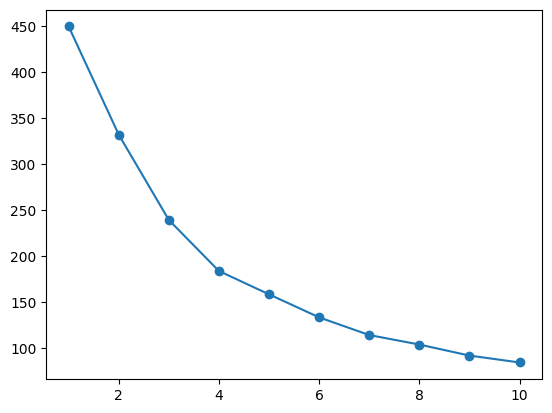

In [7]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()


### **Langkah 3 — Menjalankan K-Means (K=3).**

In [8]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())


cluster
2    52
1    51
0    47
Name: count, dtype: int64


### **Langkah 4 — Evaluasi silhouette score.**

In [9]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))


0.29732227434610753


### **Langkah 5 — Interpretasi: profil rata-rata tiap cluster.**

In [10]:
profil = df.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil


         usia  pendapatan  skor_belanja
cluster                                
0        45.3         9.9          84.3
1        28.7        10.1          30.2
2        49.9         5.3          35.5


## **D. Latihan Mandiri**

Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.

In [11]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

np.random.seed(42)

df = pd.DataFrame({
    "usia": np.random.randint(18, 66, size=150),
    "pendapatan": np.random.randint(2, 16, size=150),
    "skor_belanja": np.random.randint(1, 101, size=150)
})

X_scaled = StandardScaler().fit_transform(df)

for k in [3, 5]:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster = kmeans.fit_predict(X_scaled)
    skor = silhouette_score(X_scaled, cluster)
    print(f"K={k}, silhouette score={skor:.3f}")

K=3, silhouette score=0.297
K=5, silhouette score=0.300


Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?

kesimpulannya, bandingkan kedua nilai yang tercetak. Silhouette yang lebih tinggi menunjukkan pemisahan cluster yang lebih baik pada data tersebut. Scaling biasanya penting karena K-Means menghitung jarak, tetapi jangan langsung menyimpulkan hasil tanpa scaling selalu lebih buruk tetapi lihat skor yang benar-benar dihasilkan oleh sebuah data.

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# K=3 dengan scaling
kmeans_scaled = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_scaled = kmeans_scaled.fit_predict(X_scaled)
skor_scaled = silhouette_score(X_scaled, cluster_scaled)

# K=3 tanpa scaling
X_tanpa_scaling = df[["usia", "pendapatan", "skor_belanja"]]
kmeans_asli = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_asli = kmeans_asli.fit_predict(X_tanpa_scaling)
skor_asli = silhouette_score(X_tanpa_scaling, cluster_asli)

print(f"Silhouette dengan scaling:    {skor_scaled:.3f}")
print(f"Silhouette tanpa scaling:     {skor_asli:.3f}")

Silhouette dengan scaling:    0.297
Silhouette tanpa scaling:     0.393


Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y).

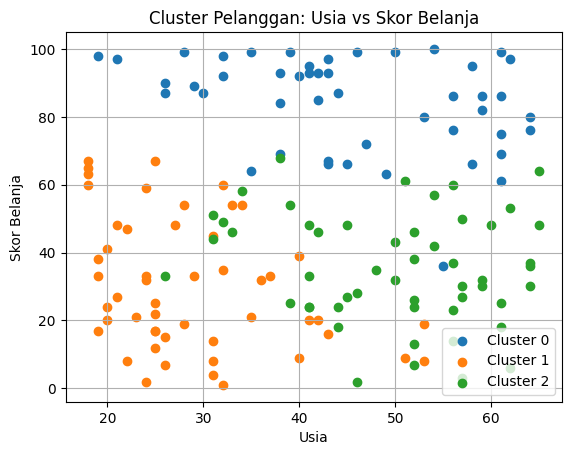

In [13]:
import matplotlib.pyplot as plt

df["cluster"] = cluster_scaled

for nomor_cluster in sorted(df["cluster"].unique()):
    data_cluster = df[df["cluster"] == nomor_cluster]
    plt.scatter(
        data_cluster["usia"],
        data_cluster["skor_belanja"],
        label=f"Cluster {nomor_cluster}"
    )

plt.xlabel("Usia")
plt.ylabel("Skor Belanja")
plt.title("Cluster Pelanggan: Usia vs Skor Belanja")
plt.legend()
plt.grid(True)
plt.show()

### **Refleksi**

**1. Bagaimana K-Means menemukan kelompok tanpa label?**

K-Means menemukan kelompok tanpa label dengan mencari kemiripan antar data berdasarkan fitur yang tersedia, misalnya usia, pendapatan, dan skor belanja. Algoritma tidak diberi tahu sebelumnya siapa yang termasuk kelompok tertentu.

Prosesnya berulang :
1. Menentukan K atau jumlah kelompok yang ingin dibuat.
2. Menempatkan titik pusat awal yang disebut centroid.
3. Memasukkan setiap data ke cluster dengan centroid terdekat.
4. Menghitung ulang centroid sebagai rata-rata anggota tiap cluster.
5. Mengulangi langkah penempatan dan pembaruan sampai posisi centroid stabil.

**2.	Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?**

Metode Elbow menunjukkan siku di K=3 karena penurunan inertia jumlah jarak kuadrat data ke centroid clusternya terlihat besar saat jumlah cluster bertambah dari K=1 ke K=3, lalu mulai melambat setelahnya.

Artinya, tiga cluster memberi keseimbangan yang cukup baik : penambahan cluster sampai K=3 banyak memperbaiki kekompakan kelompok, sementara setelah K=3 manfaat tambahannya lebih kecil. Titik siku ini membantu memilih K, tetapi bukan bukti mutlak bahwa tiga adalah jumlah cluster yang paling benar.

**3. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?**

Scaling penting karena K-Means mengelompokkan data berdasarkan jarak. Kalau rentang fitur berbeda jauh, fitur dengan angka terbesar bisa lebih mendominasi jarak.

Contohnya, pendapatan dalam jutaan rupiah bisa bernilai jutaan, sedangkan usia hanya puluhan dan skor belanja paling tinggi 100. Tanpa scaling, perbedaan pendapatan dapat lebih banyak memengaruhi pembentukan cluster. Akibatnya, pengelompokan mungkin kurang mencerminkan kontribusi yang seimbang dari usia, pendapatan, dan skor belanja.

Dengan scaling, fitur disesuaikan skalanya sebelum jarak dihitung. Jika scaling dilewatkan, cluster bisa berubah dan hasilnya berpotensi menyesatkan.